# 03 · EDA de la meteorología

**Para qué sirve este notebook.** El aire de un día depende de lo que se emite **y** del tiempo que hace: con
viento la contaminación se dispersa, con lluvia se lava, con frío y calma se acumula. Si un paro cae en un día
ventoso, el aire mejora aunque los colectivos no tengan nada que ver. Para separar las dos cosas hay que
conocer bien la meteorología del período y cómo era el tiempo en cada evento.

**Datos:** `gold_meteo_diario` (una fila por día). Fuente: registro diario del **Servicio Meteorológico
Nacional**, estaciones **Aeroparque** y **Observatorio Central (Villa Ortúzar)**. Viento, temperatura y humedad
son el promedio de las dos estaciones; la lluvia es el máximo de las dos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dónde están los Parquet: export/ del repo (local, después de `uv run python run.py`)
# o la carpeta actual (Colab: subir los .parquet de export/ con el panel de archivos).
for BASE in [Path("../export"), Path("export"), Path(".")]:
    if (BASE / "gold_analitico.parquet").exists():
        break
else:
    raise FileNotFoundError("No encuentro gold_analitico.parquet: corré `uv run python run.py` o subilo a Colab")

d = pd.read_parquet(BASE / "gold_analitico.parquet")
d["fecha"] = pd.to_datetime(d["fecha"])
eventos = pd.read_parquet(BASE / "eventos.parquet")
eventos["fecha"] = pd.to_datetime(eventos["fecha"])

ESTACIONES = ["CENTENARIO", "CORDOBA", "LA BOCA"]
# Un color fijo por estación en todos los notebooks (paleta validada para daltonismo).
COLOR = {"CENTENARIO": "#2a78d6", "CORDOBA": "#eb6834", "LA BOCA": "#1baf7a"}
# Resaltado de eventos (solo en gráficos donde no se colorea por estación).
COLOR_EVENTO = {"sin_colectivos": "#6250d6", "control": "#eda100"}
GRIS, TINTA, TINTA_2 = "#b9b8b2", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "font.size": 10, "text.color": TINTA,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format
print(f"{len(d):,} filas (estación × día), {d.fecha.min():%d/%m/%Y} a {d.fecha.max():%d/%m/%Y}")

2,950 filas (estación × día), 01/01/2024 a 30/09/2026


In [2]:
met = pd.read_parquet(BASE / "gold_meteo_diario.parquet")
cal = pd.read_parquet(BASE / "dim_calendario.parquet")
m = met.merge(cal, on="fecha")
m["fecha"] = pd.to_datetime(m["fecha"])
m = m.sort_values("fecha").reset_index(drop=True)
print(f"{len(m):,} días, {m.fecha.min():%d/%m/%Y} a {m.fecha.max():%d/%m/%Y} (el SMN publica con unos meses de atraso)")

943 días, 01/01/2024 a 31/07/2026 (el SMN publica con unos meses de atraso)


## 1. Descriptivas y calidad del dato

In [3]:
VARS = {"viento_kmh": "viento medio (km/h)", "viento_max_kmh": "ráfaga máxima (km/h)",
        "temp_c": "temperatura media (°C)", "humedad_pct": "humedad (%)", "precipitacion_mm": "lluvia (mm)"}
desc = m[list(VARS)].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.rename(index=VARS)
desc[["count", "mean", "5%", "25%", "50%", "75%", "95%", "max"]].round(1)

,count,mean,5%,25%,50%,75%,95%,max
viento medio (km/h),943.00,11.10,5.00,8.50,10.50,13.50,18.00,31.00
ráfaga máxima (km/h),943.00,37.20,22.00,30.00,37.00,44.00,57.00,76.00
temperatura media (°C),943.00,18.50,9.20,13.50,18.80,23.40,27.10,32.80
humedad (%),943.00,70.70,53.00,62.50,70.00,79.50,90.00,96.00
lluvia (mm),943.00,4.00,0.00,0.00,0.00,0.00,27.00,122.60


In [4]:
print(f"Días con viento y temperatura: {m.viento_kmh.notna().mean():.0%}")
print(f"Días sin registro de lluvia en ninguna de las dos estaciones: {m.precipitacion_sin_registro.mean():.0%}")
print(f"Días con lluvia de 1 mm o más: {m.hubo_lluvia.mean():.0%}")
lluvia_anual = m.groupby("anio").agg(dias=("fecha", "size"), dias_lluvia=("hubo_lluvia", "sum"),
                                     mm_total=("precipitacion_mm", "sum"))
lluvia_anual

Días con viento y temperatura: 100%
Días sin registro de lluvia en ninguna de las dos estaciones: 64%
Días con lluvia de 1 mm o más: 20%


,dias,dias_lluvia,mm_total
anio,,,
2024,366,76,"1,450.90"
2025,365,74,"1,715.50"
2026,212,39,616.70


**Lectura y una decisión a declarar.**
- Viento, temperatura y humedad están completos todos los días.
- **La lluvia no:** el SMN solo publica el dato de precipitación algunos días. Cuando ninguna de las dos
  estaciones tiene registro, **asumimos que no llovió**. Es razonable (en Buenos Aires llueve 1 de cada 5 días
  y el SMN suele cargar el dato cuando hay lluvia), pero es un **supuesto y va en las limitaciones**.
- Chequeo del supuesto: con él, 2024 suma unos 1.450 mm y 2025 unos 1.715 mm, por encima del promedio
  histórico de la Ciudad (del orden de 1.200 mm por año). Si el supuesto dejara afuera muchas lluvias, los
  totales darían bajos; no es el caso (que den algo altos se explica en parte porque tomamos el máximo de las
  dos estaciones). **El supuesto es razonable para este estudio.**

## 2. Estacionalidad

Mediana mensual y rango intercuartil (P25-P75) de todo el período.

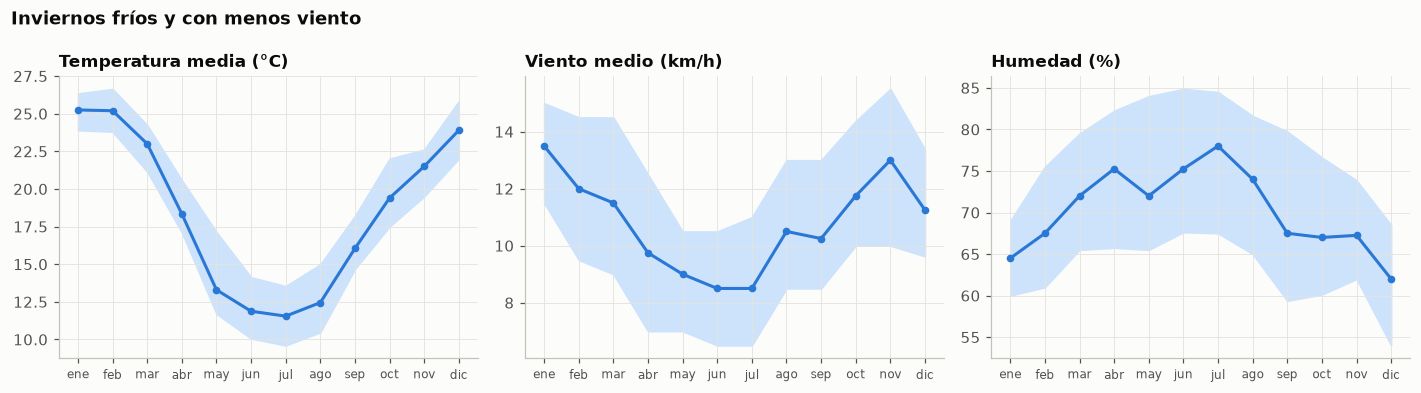

In [5]:
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (col, nombre) in zip(axes, [("temp_c", "Temperatura media (°C)"), ("viento_kmh", "Viento medio (km/h)"),
                                     ("humedad_pct", "Humedad (%)")]):
    q = m.groupby("mes")[col].quantile([0.25, 0.5, 0.75]).unstack()
    ax.fill_between(range(12), q[0.25], q[0.75], color="#cde2fb")
    ax.plot(range(12), q[0.5], color="#2a78d6", marker="o", markersize=4)
    ax.set_xticks(range(12), MESES, fontsize=8)
    ax.set_title(nombre)
fig.suptitle("Inviernos fríos y con menos viento", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

In [6]:
m.groupby("mes")[["temp_c", "viento_kmh", "humedad_pct", "hubo_lluvia"]].agg(
    {"temp_c": "median", "viento_kmh": "median", "humedad_pct": "median", "hubo_lluvia": "mean"}
).rename(index=dict(enumerate(MESES, 1)), columns={"hubo_lluvia": "% días con lluvia"}).round(2).T

mes,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
temp_c,25.25,25.20,23.00,18.35,13.30,11.88,11.55,12.45,16.05,19.40,21.50,23.90
viento_kmh,13.50,12.00,11.50,9.75,9.00,8.50,8.50,10.50,10.25,11.75,13.00,11.25
humedad_pct,64.50,67.50,72.00,75.25,72.00,75.25,78.00,74.00,67.50,67.00,67.25,62.00
% días con lluvia,0.16,0.26,0.26,0.29,0.18,0.13,0.11,0.21,0.12,0.21,0.32,0.18


**Lectura.** La temperatura media va de unos 12 °C en julio a 25 °C en enero. El viento es más débil en otoño
e invierno (mediana 8,5-9 km/h de mayo a julio) y más fuerte en primavera y verano (12-13,5 km/h). Esto, sumado a las inversiones térmicas de los días fríos, explica
por qué el NOx casi se duplica en invierno (notebook 01). Por eso el modelo del notebook 05 incluye
temperatura, viento **y el mes**.

## 3. ¿Viento y temperatura miden lo mismo? (chequeo antes de usarlos juntos en la regresión)

Si dos variables explicativas están muy correlacionadas, la regresión no puede separar sus efectos. Lo
chequeamos con la correlación y con el VIF (factor de inflación de la varianza: por debajo de 5 no hay
problema).

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = m[["viento_kmh", "temp_c", "humedad_pct"]].dropna()
X = X.assign(lluvia=m.loc[X.index, "hubo_lluvia"].astype(float), log_viento=np.log(np.maximum(X.viento_kmh, 2)))
print("Correlación de Spearman:")
print(X[["viento_kmh", "temp_c", "humedad_pct", "lluvia"]].corr(method="spearman").round(2).to_string(), "\n")
Xr = X[["log_viento", "temp_c", "lluvia"]].assign(constante=1.0)
vif = pd.Series([variance_inflation_factor(Xr.values, i) for i in range(3)], index=["log_viento", "temp_c", "lluvia"])
print("VIF de las variables del modelo:")
print(vif.round(2).to_string())

Correlación de Spearman:
             viento_kmh  temp_c  humedad_pct  lluvia
viento_kmh         1.00    0.32        -0.05    0.20
temp_c             0.32    1.00        -0.17    0.14
humedad_pct       -0.05   -0.17         1.00    0.33
lluvia             0.20    0.14         0.33    1.00 

VIF de las variables del modelo:
log_viento   1.15
temp_c       1.13
lluvia       1.05


**Lectura.** Viento y temperatura tienen una correlación moderada (0,32: en verano hay más viento), pero los
VIF están en 1,1: se pueden usar juntos en la regresión sin problema. La humedad está asociada a la lluvia
(0,33) y no se agrega al modelo: suma poca información nueva y complica la interpretación.

## 4. ¿Cómo era el tiempo en cada evento?

Cada evento comparado con los días hábiles normales **del mismo mes**: el percentil indica qué porcentaje de
esos días tuvo menos viento (o menos temperatura).

In [8]:
normales = m[m.es_dia_normal]
filas = []
for _, ev in eventos.iterrows():
    dia = m[m.fecha == ev.fecha]
    if dia.empty:
        continue
    dia = dia.iloc[0]
    ref = normales[normales.mes == ev.fecha.month]
    filas.append({"fecha": ev.fecha.date(), "evento": ev.evento, "grupo": ev.grupo,
                  "viento (km/h)": dia.viento_kmh, "percentil viento": (ref.viento_kmh < dia.viento_kmh).mean() * 100,
                  "temperatura (°C)": dia.temp_c, "percentil temp.": (ref.temp_c < dia.temp_c).mean() * 100,
                  "lluvia (mm)": dia.precipitacion_mm})
meteo_eventos = pd.DataFrame(filas).sort_values(["grupo", "fecha"], ascending=[False, True])
meteo_eventos.round(1)

,fecha,evento,grupo,viento (km/h),percentil viento,temperatura (°C),percentil temp.,lluvia (mm)
0,2024-04-11,Paro UTA,sin_colectivos,15.50,87.80,15.30,6.10,0.00
2,2024-05-09,Paro general CGT,sin_colectivos,7.50,33.30,12.20,31.50,0.00
1,2025-05-06,Paro UTA,sin_colectivos,9.50,64.80,21.00,96.30,11.10
3,2026-02-19,Paro general CGT,sin_colectivos,15.50,84.40,24.80,42.20,0.30
5,2024-10-30,Paro de trenes y subte,control,14.00,71.10,24.40,92.10,0.00
4,2025-04-10,Paro general CGT con colectivos funcionando,control,17.00,87.80,20.40,73.50,0.00


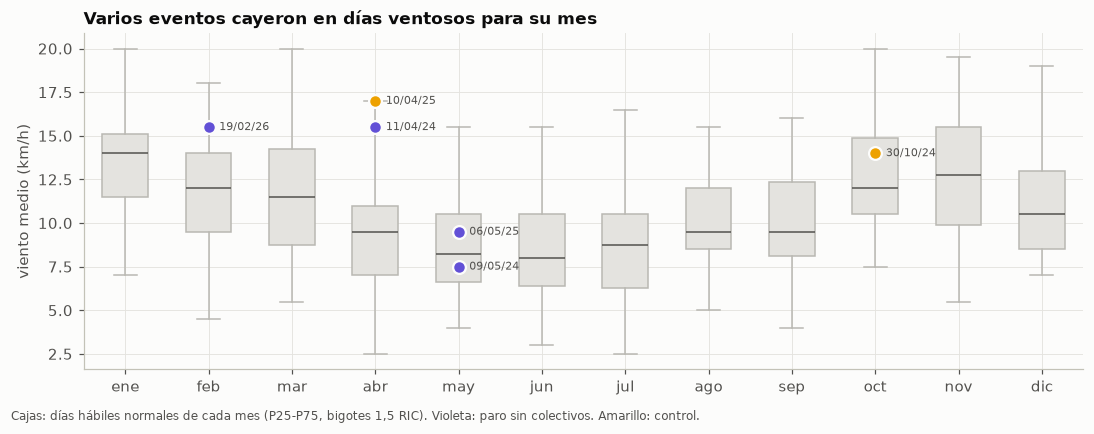

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
datos = [normales.loc[normales.mes == mes, "viento_kmh"].values for mes in range(1, 13)]
bp = ax.boxplot(datos, positions=range(12), widths=0.55, patch_artist=True, showfliers=False,
                medianprops={"color": TINTA_2}, whiskerprops={"color": GRIS}, capprops={"color": GRIS})
for caja in bp["boxes"]:
    caja.set(facecolor="#e4e3df", edgecolor=GRIS)
for _, r in meteo_eventos.iterrows():
    f = pd.Timestamp(r.fecha)
    ax.scatter(f.month - 1, r["viento (km/h)"], s=70, color=COLOR_EVENTO[r.grupo], edgecolor="#fcfcfb",
               linewidth=1.5, zorder=3)
    ax.annotate(f"{f:%d/%m/%y}", (f.month - 1, r["viento (km/h)"]), xytext=(7, 0), textcoords="offset points",
                fontsize=7.5, color=TINTA_2, va="center")
ax.set_xticks(range(12), MESES)
ax.set_ylabel("viento medio (km/h)")
ax.set_title("Varios eventos cayeron en días ventosos para su mes")
fig.text(0.01, -0.02, "Cajas: días hábiles normales de cada mes (P25-P75, bigotes 1,5 RIC). Violeta: paro sin "
         "colectivos. Amarillo: control.", fontsize=8, color=TINTA_2)
plt.tight_layout()

**Lectura.**
- **Ventosos:** el paro UTA del 11/04/2024, el paro general del 19/02/2026 y el control del 10/04/2025 están en el
  percentil 84-88 del viento de su mes. El control del 30/10/2024 también fue algo ventoso (percentil 71).
- **Calmo:** el paro general del 09/05/2024 (percentil 33).
- **Con lluvia:** el paro UTA del 06/05/2025 (11 mm), además cálido para mayo (percentil 96 de temperatura).
- **Frío:** el 11/04/2024 (percentil 6 de temperatura para abril).

**Consecuencia para el análisis:** los paros **no** cayeron todos en días tranquilos ni todos en días ventosos.
Si se los comparara sin ajustar, una parte de la caída del NOx en los días ventosos sería mérito del viento y
no del paro. Por eso el notebook 05 estima lo esperable para cada día con su viento, su temperatura y su lluvia,
y el indicador principal es el cociente NOx/CO, que el viento afecta mucho menos.

## Hallazgos del EDA meteorológico

1. **Fuente única y oficial:** SMN, Aeroparque y Observatorio Central, de enero de 2024 a julio de 2026. Viento,
   temperatura y humedad completos.
2. **Lluvia con huecos:** el 64% de los días no tiene registro de precipitación; asumimos que no llovió. Los
   totales anuales que resultan (≈1.450-1.700 mm) son coherentes con el clima de la Ciudad, así que el supuesto
   no parece dejar afuera muchas lluvias. Va en las limitaciones.
3. **Estacionalidad marcada:** inviernos fríos y con menos viento, el escenario de las peores concentraciones.
4. **Viento, temperatura y lluvia se pueden usar juntos** en la regresión (VIF ≈ 1,1).
5. **Los eventos tuvieron tiempos distintos:** dos paros sin colectivos y un control fueron ventosos para su mes,
   uno fue calmo y otro con lluvia. Comparar sin ajustar por meteorología llevaría a conclusiones equivocadas.
6. **Limitación:** el SMN da promedios de 24 h, no de la ventana de 8 a 16 h, y la lluvia es diaria (no se sabe si
   llovió de mañana o de noche).